**The Metro Interstate Traffic Volume dataset** (UCI Machine Learning Repository)
contains hourly traffic measurements for westbound Interstate 94 between Minneapolis and St. Paul, Minnesota, from October 2012 to September 2018. It has 48,204 records and 9 columns, combining traffic counts with weather conditions and holiday information. The goal is to predict traffic_volume (vehicles per hour), which makes this a regression problem.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import sklearn
print(pd.__version__, sklearn.__version__)

3.0.3 1.9.0


In [5]:
df=pd.read_csv('D:\\NTI TASKS\\the project\\Metro_Interstate_Traffic_Volume.csv')
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [6]:
df.drop_duplicates()
#17 rows dropped

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918
...,...,...,...,...,...,...,...,...,...
48199,NaN,283.45,0.0,0.0,75,Clouds,broken clouds,2018-09-30 19:00:00,3543
48200,NaN,282.76,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 20:00:00,2781
48201,NaN,282.73,0.0,0.0,90,Thunderstorm,proximity thunderstorm,2018-09-30 21:00:00,2159
48202,NaN,282.09,0.0,0.0,90,Clouds,overcast clouds,2018-09-30 22:00:00,1450


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 5.0 MB


In [8]:
df.describe()

,temp,rain_1h,snow_1h,clouds_all,traffic_volume
count,48204.000000,48204.000000,48204.000000,48204.000000,48204.000000
mean,281.205870,0.334264,0.000222,49.362231,3259.818355
std,13.338232,44.789133,0.008168,39.015750,1986.860670
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,272.160000,0.000000,0.000000,1.000000,1193.000000
50%,282.450000,0.000000,0.000000,64.000000,3380.000000
75%,291.806000,0.000000,0.000000,90.000000,4933.000000
max,310.070000,9831.300000,0.510000,100.000000,7280.000000


In [9]:
# Transforming date and extracting columns
df["date_time"] = pd.to_datetime(df["date_time"])
df["hour"] = df["date_time"].dt.hour
df["dayofweek"] = df["date_time"].dt.dayofweek
df["month"] = df["date_time"].dt.month
df["is_weekend"] = (df["dayofweek"] >= 5).astype(int) #determining weekend or workday?
df["is_weekend"].value_counts()

is_weekend
0    34501
1    13703
Name: count, dtype: int64

In [10]:
df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume,hour,dayofweek,month,is_weekend
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545,9,1,10,0
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516,10,1,10,0
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767,11,1,10,0
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026,12,1,10,0
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918,13,1,10,0


In [11]:
df.nunique()

holiday                   11
temp                    5843
rain_1h                  372
snow_1h                   12
clouds_all                60
weather_main              11
weather_description       38
date_time              40575
traffic_volume          6704
hour                      24
dayofweek                  7
month                     12
is_weekend                 2
dtype: int64

In [12]:
print((df["temp"] == 0).sum())
df = df[df["temp"] > 0] #deleting rows where temp = 0
df = df[df["rain_1h"] < 1000] #deleting the impossible rain value (9831 mm)
print(df.shape)

10
(48193, 13)


In [13]:
df.isnull().sum()

holiday                48132
temp                       0
rain_1h                    0
snow_1h                    0
clouds_all                 0
weather_main               0
weather_description        0
date_time                  0
traffic_volume             0
hour                       0
dayofweek                  0
month                      0
is_weekend                 0
dtype: int64

In [14]:
df["date_time"] = pd.to_datetime(df["date_time"])

df["date"] = df["date_time"].dt.date
holiday_dates = set(df.loc[df["holiday"].notna(), "date"]) #generalizing holiday hours
df["is_holiday"] = df["date"].isin(holiday_dates).astype(int)

df = df.drop(columns=["holiday", "date"])
print(df["is_holiday"].value_counts())

is_holiday
0    46784
1     1409
Name: count, dtype: int64


In [15]:
print(df.shape)
df = df.drop_duplicates(subset="date_time", keep="first")#droping duplicated hours with same traffic volume
print(df.shape)

(48193, 13)
(40564, 13)


In [16]:
from sklearn.preprocessing import LabelEncoder
df["weather_main"] = LabelEncoder().fit_transform(df["weather_main"])

In [17]:
df = df.drop(columns=["weather_description"])
df = df.sort_values("date_time").reset_index(drop=True)
df = df.drop(columns=["date_time"])

# Define target (date_time is already dropped and sorted in earlier cells)
X = df.drop(columns=["traffic_volume"])
y = df["traffic_volume"]

# Chronological split: 70% Train, 15% Validation, 15% Test
n = len(df)

train_end = int(n * 0.70)
val_end = int(n * 0.85)

Xtr = X.iloc[:train_end]
ytr = y.iloc[:train_end]

Xval = X.iloc[train_end:val_end]
yval = y.iloc[train_end:val_end]

Xte = X.iloc[val_end:]
yte = y.iloc[val_end:]

print("Train:", Xtr.shape, ytr.shape)
print("Validation:", Xval.shape, yval.shape)
print("Test:", Xte.shape, yte.shape)

Train: (28394, 10) (28394,)
Validation: (6085, 10) (6085,)
Test: (6085, 10) (6085,)


In [18]:
df.head(10)

,temp,rain_1h,snow_1h,clouds_all,weather_main,traffic_volume,hour,dayofweek,month,is_weekend,is_holiday
0,288.28,0.0,0.0,40,1,5545,9,1,10,0,0
1,289.36,0.0,0.0,75,1,4516,10,1,10,0,0
2,289.58,0.0,0.0,90,1,4767,11,1,10,0,0
3,290.13,0.0,0.0,90,1,5026,12,1,10,0,0
4,291.14,0.0,0.0,75,1,4918,13,1,10,0,0
5,291.72,0.0,0.0,1,0,5181,14,1,10,0,0
6,293.17,0.0,0.0,1,0,5584,15,1,10,0,0
7,293.86,0.0,0.0,1,0,6015,16,1,10,0,0
8,294.14,0.0,0.0,20,1,5791,17,1,10,0,0
9,293.10,0.0,0.0,20,1,4770,18,1,10,0,0


In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.ensemble import AdaBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor

In [20]:
lr = LinearRegression()

# Train on training data
lr.fit(Xtr, ytr)

# Predict on validation data
lr_pred = lr.predict(Xval)

# Evaluate model
print("Linear Regression - Validation Results")
print("MAE:", mean_absolute_error(yval, lr_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, lr_pred)))
print("R2:", r2_score(yval, lr_pred))

Linear Regression - Validation Results
MAE: 1530.0000062028848
RMSE: 1748.1403822086077
R2: 0.2091317262193032


In [21]:
rf = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    max_leaf_nodes=100,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf.fit(Xtr, ytr)
rf_pred = rf.predict(Xval)

print("Random Forest - Validation Results")
print("MAE:", mean_absolute_error(yval, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, rf_pred)))
print("R2:", r2_score(yval, rf_pred))

Random Forest - Validation Results
MAE: 263.2434181835045
RMSE: 412.69254370037976
R2: 0.9559237347224829


In [ ]:
dt = DecisionTreeRegressor(random_state=42)

dt.fit(Xtr, ytr)
dt_pred = dt.predict(Xval)

print("Decision Tree - Validation Results")
print("MAE:", mean_absolute_error(yval, dt_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, dt_pred)))
print("R2:", r2_score(yval, dt_pred))

Decision Tree - Validation Results
MAE: 339.7128184059162
RMSE: 555.5403118455546
R2: 0.9201301810320694


In [ ]:
# Create KNN Model
knn = KNeighborsRegressor(n_neighbors=5)

# Train
knn.fit(Xtr, ytr)

# Prediction on Validation
knn_pred = knn.predict(Xval)

# Evaluation
print("KNN - Validation Results")
print("MAE:", mean_absolute_error(yval, knn_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, knn_pred)))
print("R2:", r2_score(yval, knn_pred))

KNN - Validation Results
MAE: 497.4462777321282
RMSE: 752.3790390439975
R2: 0.8535042858936017


In [ ]:
svr = SVR(kernel="rbf")

svr.fit(Xtr, ytr)
svr_pred = svr.predict(Xval)

print("SVR - Validation Results")
print("MAE:", mean_absolute_error(yval, svr_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, svr_pred)))
print("R2:", r2_score(yval, svr_pred))

SVR - Validation Results
MAE: 1704.4567366456142
RMSE: 1953.3910711052285
R2: 0.012516290039858768


In [ ]:
ada = AdaBoostRegressor(
    n_estimators=100,
    random_state=42
)

ada.fit(Xtr, ytr)
ada_pred = ada.predict(Xval)

print("AdaBoost - Validation Results")
print("MAE:", mean_absolute_error(yval, ada_pred))
print("RMSE:", np.sqrt(mean_squared_error(yval, ada_pred)))
print("R2:", r2_score(yval, ada_pred))

AdaBoost - Validation Results
MAE: 599.52486441305
RMSE: 794.4939516481119
R2: 0.8366448863160622


               Model          MAE         RMSE        R2
1      Random Forest   263.243418   412.692544  0.955924
3      Decision Tree   339.712818   555.540312  0.920130
2                KNN   497.446278   752.379039  0.853504
5           AdaBoost   599.524864   794.493952  0.836645
0  Linear Regression  1530.000006  1748.140382  0.209132
4                SVR  1704.456737  1953.391071  0.012516


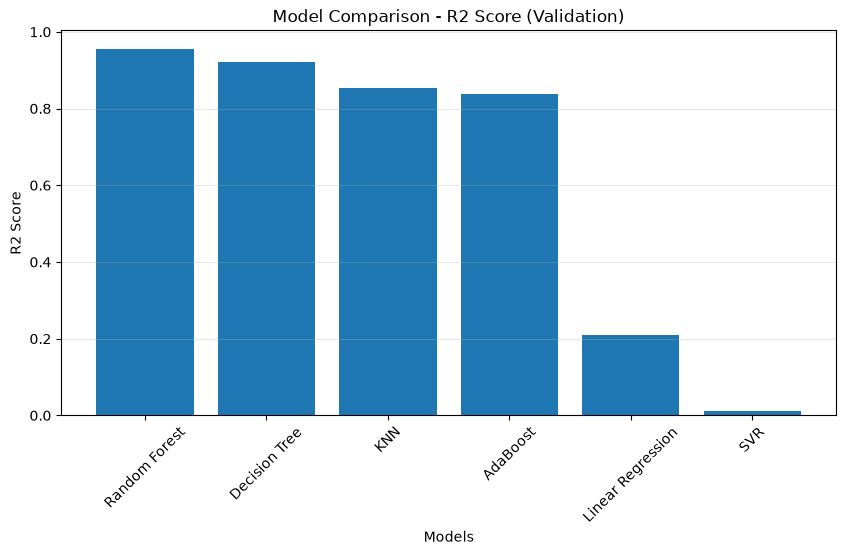

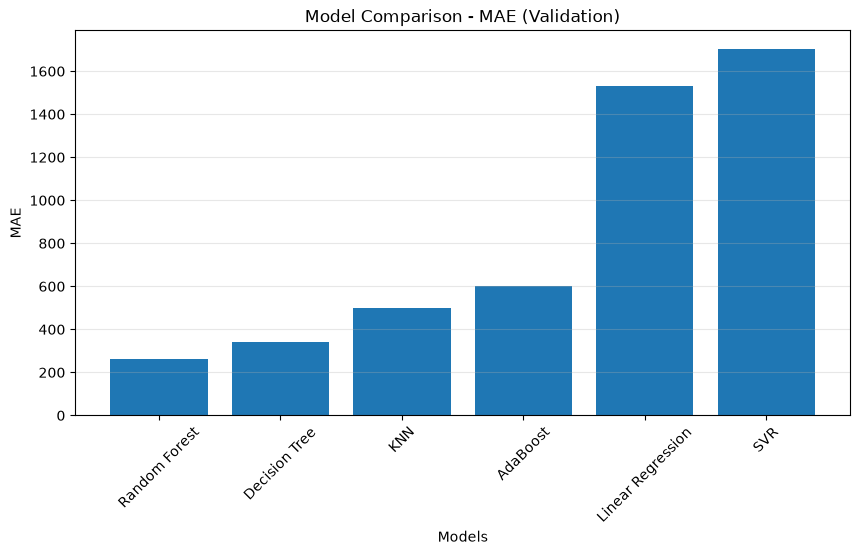

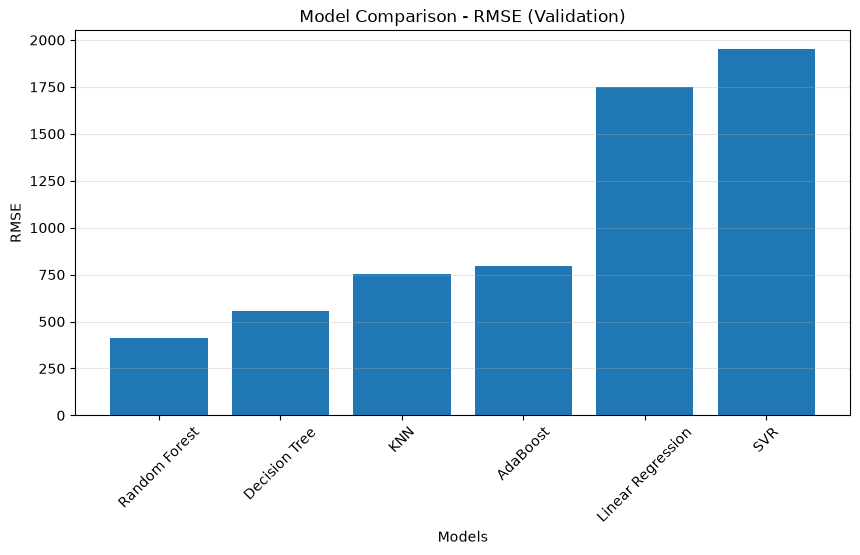

In [26]:
# Store model predictions
models_metrics = {
    "Linear Regression": lr_pred,
    "Random Forest": rf_pred,
    "KNN": knn_pred,
    "Decision Tree": dt_pred,
    "SVR": svr_pred,
    "AdaBoost": ada_pred
}

# Calculate evaluation metrics
results = []

for name, pred in models_metrics.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(yval, pred),
        "RMSE": np.sqrt(mean_squared_error(yval, pred)),
        "R2": r2_score(yval, pred)
    })

results_df = pd.DataFrame(results)

# Sort models by R2 (Best first)
results_df = results_df.sort_values(by="R2", ascending=False)

print(results_df)

# R2 Comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["R2"])
plt.title("Model Comparison - R2 Score (Validation)")
plt.xlabel("Models")
plt.ylabel("R2 Score")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

# MAE Comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["MAE"])
plt.title("Model Comparison - MAE (Validation)")
plt.xlabel("Models")
plt.ylabel("MAE")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()

# RMSE Comparison
plt.figure(figsize=(10, 5))
plt.bar(results_df["Model"], results_df["RMSE"])
plt.title("Model Comparison - RMSE (Validation)")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.show()


In [27]:

models = {
    "Linear Regression": lr,
    "Random Forest": rf,
    "KNN": knn,
    "Decision Tree": dt,
    "SVR": svr,
    "AdaBoost": ada
}

results = []

for name, model in models.items():

    # Predictions
    train_pred = model.predict(Xtr)
    val_pred = model.predict(Xval)
    test_pred = model.predict(Xte)

    # Train Metrics
    results.append({
        "Model": name,
        "Dataset": "Train",
        "MAE": mean_absolute_error(ytr, train_pred),
        "RMSE": np.sqrt(mean_squared_error(ytr, train_pred)),
        "R2 Score": r2_score(ytr, train_pred)
    })

    # Validation Metrics
    results.append({
        "Model": name,
        "Dataset": "Validation",
        "MAE": mean_absolute_error(yval, val_pred),
        "RMSE": np.sqrt(mean_squared_error(yval, val_pred)),
        "R2 Score": r2_score(yval, val_pred)
    })

    # Test Metrics
    results.append({
        "Model": name,
        "Dataset": "Test",
        "MAE": mean_absolute_error(yte, test_pred),
        "RMSE": np.sqrt(mean_squared_error(yte, test_pred)),
        "R2 Score": r2_score(yte, test_pred)
    })

# Create Results DataFrame
results_df = pd.DataFrame(results)

results_df[["MAE", "RMSE", "R2 Score"]] = results_df[
    ["MAE", "RMSE", "R2 Score"]
].round(4)

display(results_df)


,Model,Dataset,MAE,RMSE,R2 Score
0,Linear Regression,Train,1570.6902,1788.9002,0.1913
1,Linear Regression,Validation,1530.0000,1748.1404,0.2091
2,Linear Regression,Test,1553.9688,1772.5935,0.1980
3,Random Forest,Train,272.3107,414.9239,0.9565
4,Random Forest,Validation,263.2434,412.6925,0.9559
5,Random Forest,Test,249.9815,392.9660,0.9606
6,KNN,Train,362.3917,541.7722,0.9258
7,KNN,Validation,497.4463,752.3790,0.8535
8,KNN,Test,462.2497,702.3658,0.8741
9,Decision Tree,Train,0.2515,15.7532,0.9999


In [30]:
estimators = [
    ('rf', RandomForestRegressor(
        n_estimators=200,
        random_state=42
    )),

    ('knn', Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=5))
    ])),

    ('dt', DecisionTreeRegressor(
        max_depth=10,
        random_state=42
    ))
]

stacking_model = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(),
    cv=5
)


stacking_model.fit(Xtr, ytr)

y_pred = stacking_model.predict(Xte)

In [31]:
models = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'KNN': knn,
    'Decision Tree': dt,
    'SVR': svr,
    'AdaBoost': ada,
    'Stacking Regressor': stacking_model
}

datasets = {
    'Train': (Xtr, ytr),
    'Validation': (Xval, yval),
    'Test': (Xte, yte)
}

results = []

for model_name, model in models.items():
    for dataset_name, (X, y) in datasets.items():
        y_pred = model.predict(X)
        results.append({
            'Model': model_name,
            'Dataset': dataset_name,
            'MAE': mean_absolute_error(y, y_pred),
            'RMSE': np.sqrt(mean_squared_error(y, y_pred)),
            'R2 Score': r2_score(y, y_pred)
        })

results_df = pd.DataFrame(results)
print(results_df.round(4).to_string(index=False))
results_df.to_csv('all_models_comparison.csv', index=False)

             Model    Dataset       MAE      RMSE  R2 Score
 Linear Regression      Train 1570.6902 1788.9002    0.1913
 Linear Regression Validation 1530.0000 1748.1404    0.2091
 Linear Regression       Test 1553.9688 1772.5935    0.1980
     Random Forest      Train  272.3107  414.9239    0.9565
     Random Forest Validation  263.2434  412.6925    0.9559
     Random Forest       Test  249.9815  392.9660    0.9606
               KNN      Train  362.3917  541.7722    0.9258
               KNN Validation  497.4463  752.3790    0.8535
               KNN       Test  462.2497  702.3658    0.8741
     Decision Tree      Train    0.2515   15.7532    0.9999
     Decision Tree Validation  339.7128  555.5403    0.9201
     Decision Tree       Test  319.7720  539.1256    0.9258
               SVR      Train 1740.3962 1985.6374    0.0036
               SVR Validation 1704.4567 1953.3911    0.0125
               SVR       Test 1720.6985 1969.8264    0.0095
          AdaBoost      Train  592.4943 